In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import plotly.express as px
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("StudentsPerformance.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [6]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [7]:
print("Number of rows: ", df.shape[0])
print("Number of columns: ", df.shape[1])

Number of rows:  1000
Number of columns:  8


In [8]:
print(df.columns.tolist())

['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [10]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [11]:
print(df.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [14]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


In [15]:
marks = np.array([72,69,90,47,76,85,60])
print("Marks: ", marks)
print("First mark: ", marks[0])
print("First three marks: ", marks[:3])
print("Marks after adding 5: ",marks + 5)

Marks:  [72 69 90 47 76 85 60]
First mark:  72
First three marks:  [72 69 90]
Marks after adding 5:  [77 74 95 52 81 90 65]


In [16]:
math_marks =df["math score"].to_numpy()

print("Mean: ", np.mean(math_marks))
print("Median: ", np.median(math_marks))
print("Standard deviation: ", np.std(math_marks))
print("Minimum: ", np.min(math_marks))
print("Maximum: ", np.max(math_marks))
print("25th percentile: ",np.percentile(math_marks, 25))
print("75th percentile: ",np.percentile(math_marks, 75))

Mean:  66.089
Median:  66.0
Standard deviation:  15.155496659628149
Minimum:  0
Maximum:  100
25th percentile:  57.0
75th percentile:  77.0


In [18]:
original_rows = len(df)
print("Rows before cleaning: ", original_rows)

Rows before cleaning:  1000


In [19]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+","_",regex=True)
    .str.strip("_")
)
print(df.columns.tolist())

['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


In [22]:
df = df.drop_duplicates().copy()
numeric_columns = df.select_dtypes(include="number").columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])
print("Rows after cleaning : ", len(df))
print("Remaining missing values: ", df.isnull().sum().sum()) 

Rows after cleaning :  1000
Remaining missing values:  0


In [23]:
print("Rows before cleaning: ", original_rows)
print("Rows after cleaning: ", len(df))
print("Rows removed: ", original_rows - len(df))

Rows before cleaning:  1000
Rows after cleaning:  1000
Rows removed:  0


In [24]:
numeric_cols =[
    "math_score",
    "reading_score",
    "writing_score"
]

df[numeric_cols].describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [26]:
print("Gender distribution:")
print(df["gender"].value_counts())

print("\nTest preparation course:")
print(df["test_preparation_course"].value_counts())

print("\nParental level of education:")
print(df["parental_level_of_education"].value_counts())


Gender distribution:
gender
female    518
male      482
Name: count, dtype: int64

Test preparation course:
test_preparation_course
none         642
completed    358
Name: count, dtype: int64

Parental level of education:
parental_level_of_education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64


In [28]:
df.groupby("gender")[numeric_cols].mean().round(2)

,math_score,reading_score,writing_score
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


In [29]:
correlation = df[numeric_cols].corr()
print(correlation.round(2))

               math_score  reading_score  writing_score
math_score           1.00           0.82           0.80
reading_score        0.82           1.00           0.95
writing_score        0.80           0.95           1.00


In [30]:
print("OBSERVATION 1: Average marks")
print(df[numeric_cols].mean().round(2))

print("\nOBSERVATION 2: Highest average score")
print(df[numeric_cols].mean().idxmax())

print("\nOBSERVATION 3: Lowest average score")
print(df[numeric_cols].mean().idxmin())

print("\nOBSERVATION 4: Correlation between reading and writing")
print(round(df["reading_score"].corr(df["writing_score"]), 2))

print("\nOBSERVATION 5: Average scores by test preparation")
print(
    df.groupby("test_preparation_course")[numeric_cols]
      .mean()
      .round(2)
)

OBSERVATION 1: Average marks
math_score       66.09
reading_score    69.17
writing_score    68.05
dtype: float64

OBSERVATION 2: Highest average score
reading_score

OBSERVATION 3: Lowest average score
math_score

OBSERVATION 4: Correlation between reading and writing
0.95

OBSERVATION 5: Average scores by test preparation
                         math_score  reading_score  writing_score
test_preparation_course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50


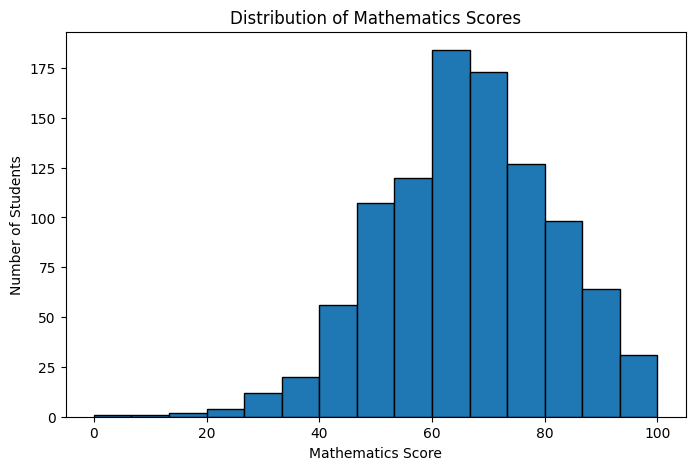

In [31]:
plt.figure(figsize=(8, 5))
plt.hist(df["math_score"], bins=15, edgecolor="black")
plt.title("Distribution of Mathematics Scores")
plt.xlabel("Mathematics Score")
plt.ylabel("Number of Students")
plt.show()

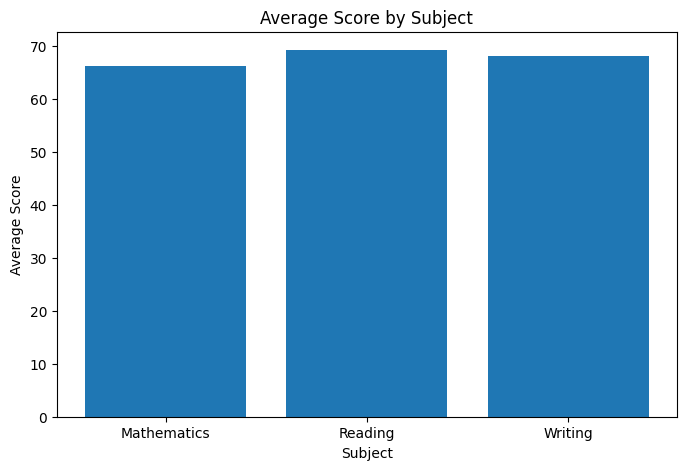

In [32]:
subject_means = df[numeric_cols].mean()

plt.figure(figsize=(8, 5))
plt.bar(
    ["Mathematics", "Reading", "Writing"],
    subject_means.values
)
plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.show()

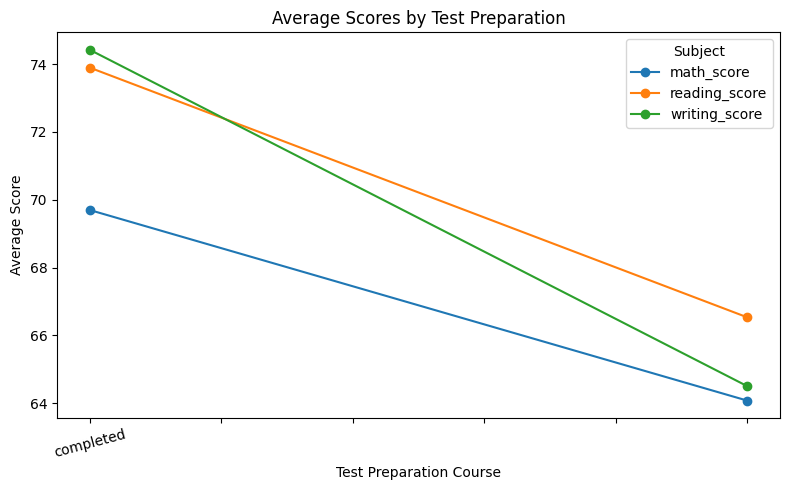

In [33]:
prep_scores = df.groupby("test_preparation_course")[
    numeric_cols
].mean()

prep_scores.plot(marker="o", figsize=(8, 5))
plt.title("Average Scores by Test Preparation")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=15)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

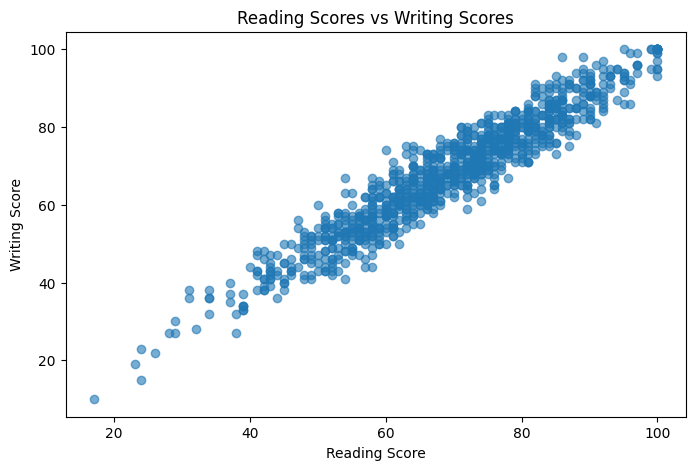

In [34]:
plt.figure(figsize=(8, 5))
plt.scatter(df["reading_score"], df["writing_score"], alpha=0.6)
plt.title("Reading Scores vs Writing Scores")
plt.xlabel("Reading Score")
plt.ylabel("Writing Score")
plt.show()

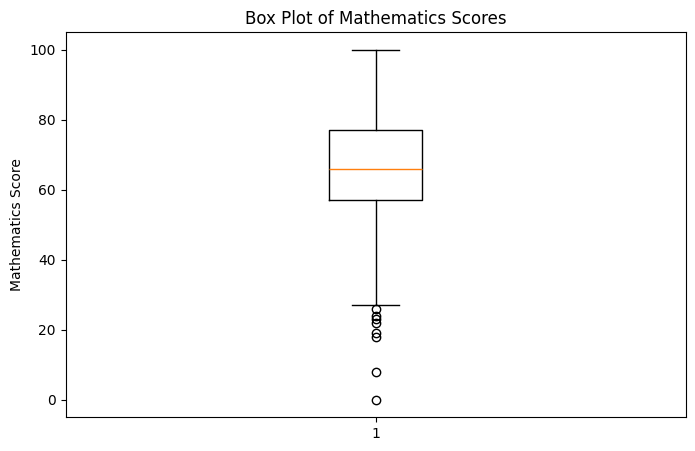

In [36]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["math_score"])
plt.title("Box Plot of Mathematics Scores")
plt.ylabel("Mathematics Score")
plt.show()

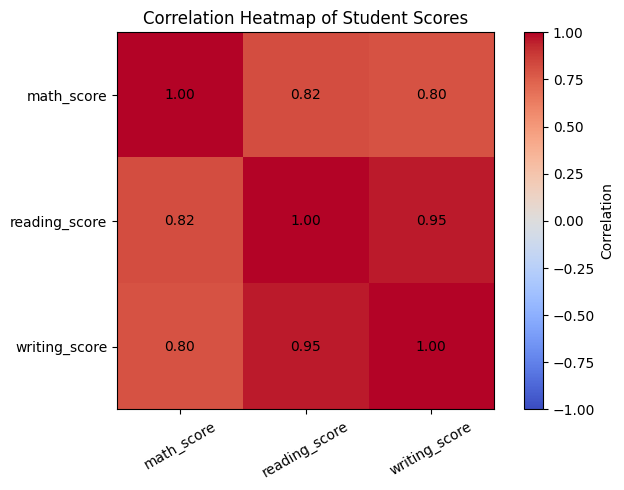

In [37]:
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=30)
plt.yticks(range(len(numeric_cols)), numeric_cols)

for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Heatmap of Student Scores")
plt.tight_layout()
plt.show()

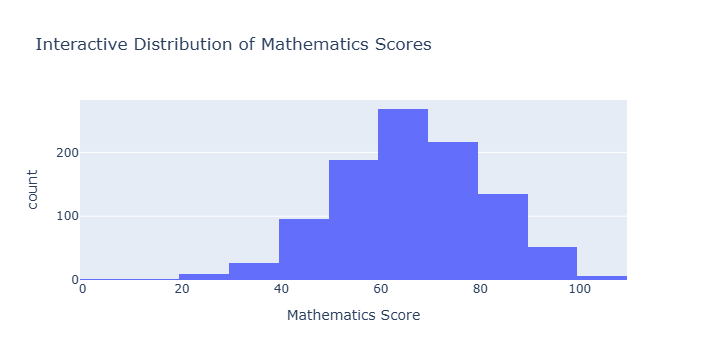

In [38]:
fig = px.histogram(
    df,
    x="math_score",
    nbins=15,
    title="Interactive Distribution of Mathematics Scores",
    labels={"math_score": "Mathematics Score"}
)

fig.show()


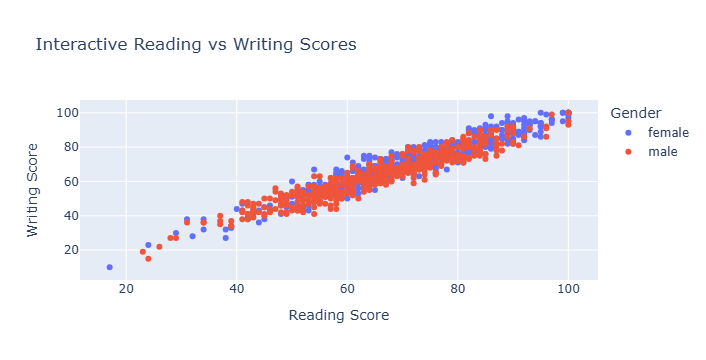

In [39]:
fig = px.scatter(
    df,
    x="reading_score",
    y="writing_score",
    color="gender",
    title="Interactive Reading vs Writing Scores",
    labels={
        "reading_score": "Reading Score",
        "writing_score": "Writing Score",
        "gender": "Gender"
    },
    hover_data=["math_score"]
)

fig.show()

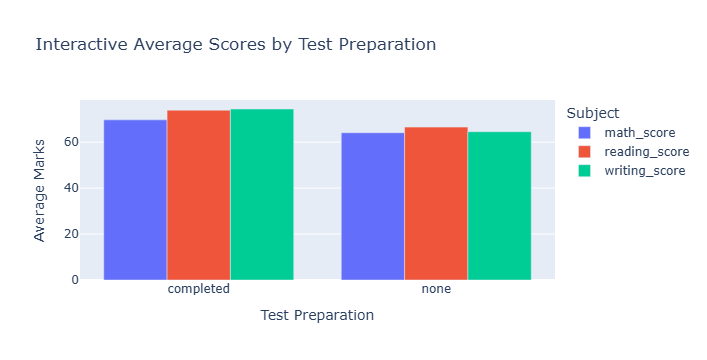

In [40]:
plot_data = df.groupby("test_preparation_course", as_index=False)[
    numeric_cols
].mean()

plot_data = plot_data.melt(
    id_vars="test_preparation_course",
    var_name="Subject",
    value_name="Average Score"
)

fig = px.bar(
    plot_data,
    x="test_preparation_course",
    y="Average Score",
    color="Subject",
    barmode="group",
    title="Interactive Average Scores by Test Preparation",
    labels={
        "test_preparation_course": "Test Preparation",
        "Average Score": "Average Marks"
    },
    hover_data={"Average Score": ":.2f"}
)

fig.show()

In [41]:
df_features = df.copy()

df_features["total_score"] = (
    df_features["math_score"]
    + df_features["reading_score"]
    + df_features["writing_score"]
)

df_features["average_score"] = (
    df_features["total_score"] / 3
).round(2)

df_features["score_range"] = (
    df_features[numeric_cols].max(axis=1)
    - df_features[numeric_cols].min(axis=1)
)

df_features[
    numeric_cols + ["total_score", "average_score", "score_range"]
].head()

,math_score,reading_score,writing_score,total_score,average_score,score_range
0,72,72,74,218,72.67,2
1,69,90,88,247,82.33,21
2,90,95,93,278,92.67,5
3,47,57,44,148,49.33,13
4,76,78,75,229,76.33,3


In [42]:
df_features["performance_category"] = np.where(
    df_features["average_score"] >= 70,
    "High",
    "Below 70"
)

df_features[
    ["average_score", "performance_category"]
].head()

,average_score,performance_category
0,72.67,High
1,82.33,High
2,92.67,High
3,49.33,Below 70
4,76.33,High


In [43]:
categorical_cols = [
    "gender",
    "race_ethnicity",
    "parental_level_of_education",
    "lunch",
    "test_preparation_course"
]

df_encoded = pd.get_dummies(
    df_features,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

df_encoded.head()

,math_score,reading_score,writing_score,total_score,average_score,score_range,performance_category,gender_female,gender_male,race_ethnicity_group A,...,parental_level_of_education_associate's degree,parental_level_of_education_bachelor's degree,parental_level_of_education_high school,parental_level_of_education_master's degree,parental_level_of_education_some college,parental_level_of_education_some high school,lunch_free/reduced,lunch_standard,test_preparation_course_completed,test_preparation_course_none
0,72,72,74,218,72.67,2,High,1,0,0,...,0,1,0,0,0,0,0,1,0,1
1,69,90,88,247,82.33,21,High,1,0,0,...,0,0,0,0,1,0,0,1,1,0
2,90,95,93,278,92.67,5,High,1,0,0,...,0,0,0,1,0,0,0,1,0,1
3,47,57,44,148,49.33,13,Below 70,0,1,1,...,1,0,0,0,0,0,1,0,0,1
4,76,78,75,229,76.33,3,High,0,1,0,...,0,0,0,0,1,0,0,1,0,1


In [46]:
from sklearn.preprocessing import StandardScaler

scale_cols = numeric_cols + [
    "total_score",
    "average_score",
    "score_range"
]

scaler = StandardScaler()

df_scaled = df_features.copy()
df_scaled[scale_cols] = scaler.fit_transform(
    df_scaled[scale_cols]
)

df_scaled[scale_cols].head()

,math_score,reading_score,writing_score,total_score,average_score,score_range
0,0.390024,0.193999,0.391492,0.343574,0.343815,-1.474236
1,0.192076,1.427476,1.313269,1.021927,1.021701,2.121923
2,1.577711,1.770109,1.642475,1.747064,1.747306,-0.906421
3,-1.259543,-0.833899,-1.583744,-1.293830,-1.294059,0.607751
4,0.653954,0.605158,0.457333,0.600881,0.600653,-1.284964


In [47]:
print("Original dataset shape:", df.shape)
print("Feature-engineered dataset shape:", df_features.shape)
print("Encoded dataset shape:", df_encoded.shape)
print("Scaled dataset shape:", df_scaled.shape)

df_features.head()

Original dataset shape: (1000, 8)
Feature-engineered dataset shape: (1000, 12)
Encoded dataset shape: (1000, 24)
Scaled dataset shape: (1000, 12)


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score,score_range,performance_category
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.67,2,High
1,female,group C,some college,standard,completed,69,90,88,247,82.33,21,High
2,female,group B,master's degree,standard,none,90,95,93,278,92.67,5,High
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.33,13,Below 70
4,male,group C,some college,standard,none,76,78,75,229,76.33,3,High


In [ ]:
# Conclusion

The Student Performance Analysis project uses Python libraries such as NumPy, Pandas, Matplotlib, and Plotly to explore student examination data.

Data preprocessing was performed to inspect missing values, identify duplicate records, standardize column names, and prepare the data for analysis.

Exploratory Data Analysis was used to examine descriptive statistics, compare subject scores, study categorical variables, and investigate correlations. Matplotlib charts and interactive Plotly visualizations were created to present the findings clearly.

Feature engineering was performed by creating total score, average score, and score range. Categorical encoding and numerical scaling were also demonstrated.

The analysis provides a structured understanding of the dataset. However, the results show associations rather than proof of cause and effect.

## Recommendations

1. Compare performance across subjects to identify areas that may need additional academic support.
2. Examine the relationship between test preparation and scores without assuming that preparation alone causes better performance.
3. Use the engineered features for further analysis or future predictive modeling.

## Limitations

1. The dataset contains examination scores and selected background characteristics, not every factor that can affect student performance.
2. The findings may not represent students from all schools or regions.
3. Correlation does not establish causation.
4. The performance categories used in this project are illustrative and should not be treated as official grading rules.